In [1]:
import pandas as pd
import numpy as np
import duckdb
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

conn = duckdb.connect()
print("DuckDB подключен")

DuckDB подключен


In [2]:
metrics_query = """
WITH user_stats AS (
    SELECT 
        wallet_address,
        MIN(CAST(tx_date AS DATE)) as first_tx_date,
        COUNT(*) as total_txs,
        SUM(amount_usd) as total_volume,
        SUM(fee_usd) as ltv_revenue
    FROM read_csv_auto('crypto_txs.csv')
    GROUP BY wallet_address
)
SELECT 
    COUNT(wallet_address) as total_users,
    ROUND(AVG(total_volume), 2) as arpu_volume_usd,
    ROUND(AVG(ltv_revenue), 2) as average_ltv_usd
FROM user_stats;
"""
display(conn.execute(metrics_query).df())

,total_users,arpu_volume_usd,average_ltv_usd
0,1000,5157.82,51.58


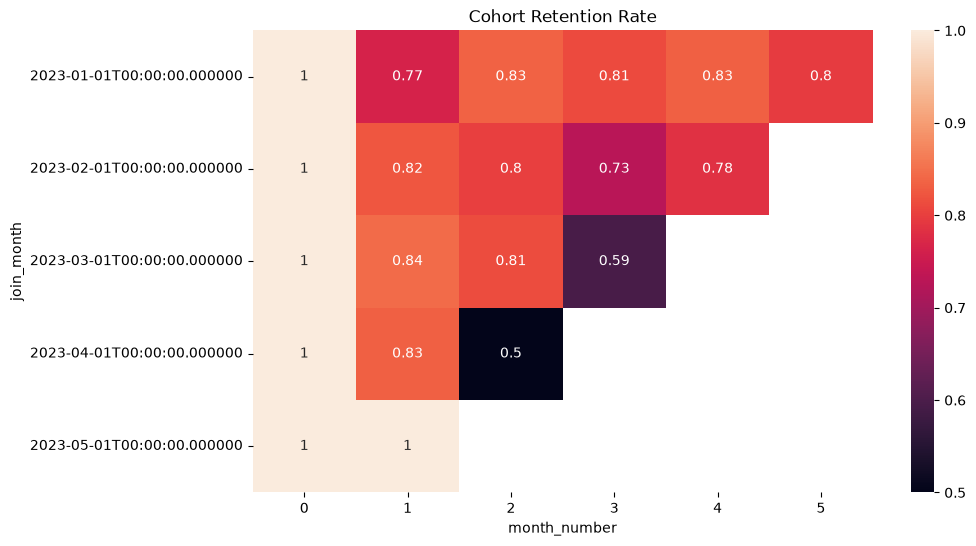

In [3]:
cohort_query = """
WITH user_cohorts AS (
    SELECT 
        wallet_address,
        date_trunc('month', CAST(tx_date AS DATE)) AS cohort_month,
        CAST(tx_date AS DATE) AS tx_date
    FROM read_csv_auto('crypto_txs.csv')
),
first_touch AS (
    SELECT 
        wallet_address,
        MIN(cohort_month) AS join_month
    FROM user_cohorts
    GROUP BY wallet_address
)
SELECT 
    f.join_month,
    date_diff('month', f.join_month, u.cohort_month) AS month_number,
    COUNT(DISTINCT u.wallet_address) AS active_users
FROM user_cohorts u
JOIN first_touch f ON u.wallet_address = f.wallet_address
GROUP BY 1, 2
ORDER BY 1, 2;
"""
cohorts_df = conn.execute(cohort_query).df()

retention_matrix = cohorts_df.pivot(index='join_month', columns='month_number', values='active_users')
retention_size = retention_matrix.iloc[:,0]
retention_rate = retention_matrix.divide(retention_size, axis=0)

plt.figure(figsize=(10, 6))
sns.heatmap(retention_rate, annot=True)
plt.title('Cohort Retention Rate')
plt.show()

cohorts_df.to_csv('powerbi_cohorts.csv', index=False)

In [4]:
ab_query = """
SELECT ab_group, amount_usd 
FROM read_csv_auto('crypto_txs.csv')
"""
ab_df = conn.execute(ab_query).df()

group_a = ab_df[ab_df['ab_group'] == 'A']['amount_usd']
group_b = ab_df[ab_df['ab_group'] == 'B']['amount_usd']

t_stat, p_value = stats.ttest_ind(group_a, group_b, equal_var=False)
print(f"T-Test p-value: {p_value:.5f}")
if p_value < 0.05:
    print("Вывод: Разница статистически значима")
else:
    print("Вывод: Разница не значима")

n_iterations = 1000
diffs = []
for _ in range(n_iterations):
    sample_a = np.random.choice(group_a, size=len(group_a), replace=True)
    sample_b = np.random.choice(group_b, size=len(group_b), replace=True)
    diffs.append(np.mean(sample_b) - np.mean(sample_a))

ci_lower, ci_upper = np.percentile(diffs, [2.5, 97.5])
print(f"Bootstrap 95% CI для разницы средних чеков: [{ci_lower:.2f}$, {ci_upper:.2f}$]")

T-Test p-value: 0.00000
Вывод: Разница статистически значима
Bootstrap 95% CI для разницы средних чеков: [57.16$, 113.40$]


ROC-AUC Score: 0.910


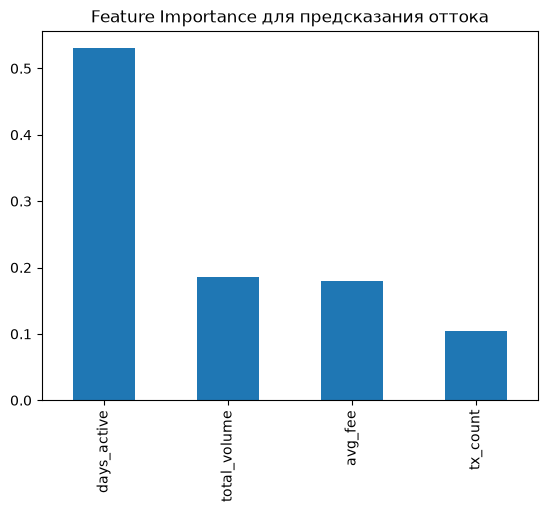

In [5]:
features_query = """
WITH user_metrics AS (
    SELECT 
        wallet_address,
        COUNT(*) AS tx_count,
        SUM(amount_usd) AS total_volume,
        AVG(fee_usd) AS avg_fee,
        MAX(CAST(tx_date AS DATE)) AS last_tx_date,
        MAX(CAST(tx_date AS DATE)) - MIN(CAST(tx_date AS DATE)) AS days_active
    FROM read_csv_auto('crypto_txs.csv')
    GROUP BY wallet_address
)
SELECT 
    *,
    CASE WHEN date_diff('day', last_tx_date, DATE '2023-06-30') > 30 THEN 1 ELSE 0 END AS is_churn
FROM user_metrics;
"""
ml_df = conn.execute(features_query).df()
ml_df.to_csv('powerbi_ml_users.csv', index=False)

X = ml_df[['tx_count', 'total_volume', 'avg_fee', 'days_active']]
y = ml_df['is_churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_proba = rf_model.predict_proba(X_test)[:, 1]
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.3f}")

feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
feature_importances.plot(kind='bar', title='Feature Importance для предсказания оттока')
plt.show()